# OCR et image captioning



# OCR : évaluer la transcription

**Objectif :** calculer CER, WER et exactitude sur une vraie sortie de Tesseract
Dans Colab : importer le ZIP du projet dans le panneau Fichiers


In [16]:

# !pip -q install -r requirements.txt
# !apt-get -qq update && apt-get -qq install -y tesseract-ocr


In [17]:
!git clone https://github.com/Et-taky/metric_evaluation_IA_avancee.git

fatal: destination path 'metric_evaluation_IA_avancee' already exists and is not an empty directory.


In [18]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd

# Définir la racine du projet cloné
ROOT = Path("/content/metric_evaluation_IA_avancee")

# Vérifier la structure
assert (ROOT / "src").exists(), "Le dossier src est introuvable"

# Ajouter le projet au Python path
sys.path.insert(0, str(ROOT))

# Créer le dossier results s'il n'existe pas
(ROOT / "results").mkdir(exist_ok=True)

print("Projet chargé avec succès :", ROOT)
print("Dossiers disponibles :", [p.name for p in ROOT.iterdir()])

Projet chargé avec succès : /content/metric_evaluation_IA_avancee
Dossiers disponibles : ['README.md', 'src', '.gitignore', 'results', 'presentations', 'data', '.git', 'requirements.txt', 'notebooks']


## 1. Créer des images dont on connaît le texte
La vérité terrain est écrite avant la reconnaissance. Les images incluent une ligne nette, une ligne peu lisible et une référence proche visuellement de chiffres. Le français des explications est conservé ; le moteur `eng` suffit ici car les trois lignes ne contiennent aucun accent.


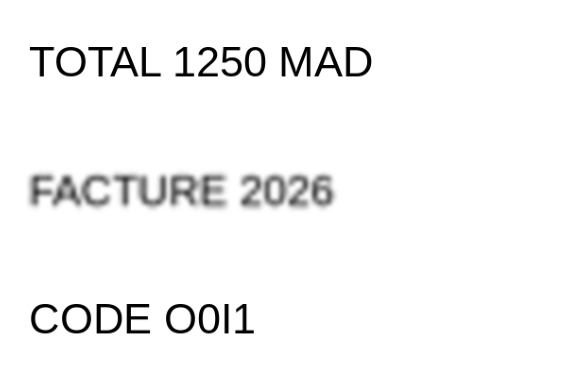

Images générées avec succès.
Police utilisée : /usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf
Résultats : /content/metric_evaluation_IA_avancee/results/ocr_images.png


In [19]:
from PIL import Image, ImageDraw, ImageFont, ImageFilter
from pathlib import Path
import shutil
import subprocess
import tempfile
import matplotlib.pyplot as plt

# 1. Références OCR
refs = [
    "TOTAL 1250 MAD",
    "FACTURE 2026",
    "CODE O0I1"
]

# 2. Trouver automatiquement une police disponible
possible_fonts = [
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
    "/usr/share/fonts/truetype/liberation2/LiberationSans-Regular.ttf",
    "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf"
]

font_path = next(
    (p for p in possible_fonts if Path(p).exists()),
    None
)

# Installer une police si nécessaire
if font_path is None:
    !apt-get update -qq
    !apt-get install -y fonts-dejavu-core

    font_path = "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"

font = ImageFont.truetype(font_path, 45)

# 3. Créer les dossiers nécessaires
(ROOT / "data").mkdir(parents=True, exist_ok=True)
(ROOT / "results").mkdir(parents=True, exist_ok=True)

# 4. Générer les images
images = []

for i, ref in enumerate(refs):

    image = Image.new("RGB", (600, 120), "white")
    draw = ImageDraw.Draw(image)

    draw.text((20, 30), ref, font=font, fill="black")

    # Dégradation artificielle de la deuxième image
    if i == 1:
        image = (
            image.resize((120, 24))
                 .resize((600, 120))
                 .filter(ImageFilter.GaussianBlur(1.4))
        )

    images.append(image)

    image.save(ROOT / f"data/ocr_{i}.png")

# 5. Visualisation
fig, axes = plt.subplots(3, 1, figsize=(10, 4))

for ax, image in zip(axes, images):
    ax.imshow(image)
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    ROOT / "results/ocr_images.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()

print("Images générées avec succès.")
print("Police utilisée :", font_path)
print("Résultats :", ROOT / "results/ocr_images.png")

## 2. Reconnaître puis normaliser de manière identique
`--psm 7` indique une ligne de texte. On réduit les espaces consécutifs et on ignore la casse des deux côtés. La ponctuation et les confusions O/0 restent des erreurs. Le moteur n’est pas entraîné ici.


In [20]:
if not shutil.which("tesseract"):
    raise RuntimeError("Installer Tesseract puis relancer cette cellule")
preds = []
for i in range(len(images)):
    output = subprocess.run(["tesseract",str(ROOT/f"data/ocr_{i}.png"),"stdout",
                             "-l","eng","--psm","7"],capture_output=True,text=True,check=True)
    preds.append(" ".join(output.stdout.upper().split()))
refs = [" ".join(r.upper().split()) for r in refs]
print(pd.DataFrame({"Référence":refs,"Prédiction OCR":preds}).to_string(index=False))


     Référence Prédiction OCR
TOTAL 1250 MAD TOTAL 1250 MAD
  FACTURE 2026   FACTURE 2026
     CODE O0I1     CODE OOLI1


## 3. Calculer CER et WER
Pour chaque niveau, taux = (substitutions + suppressions + insertions) / nombre d’unités de référence. Le CER inclut les espaces. Le WER utilise les mots séparés par des espaces. On additionne les éditions avant de diviser : ce n’est pas la moyenne des taux par ligne.


In [21]:
from src.metrics import distance, error_rates
scores = error_rates(refs,preds)
print(pd.Series(scores).map(lambda x:f"{x:.2%}"))
(ROOT/"results/ocr_scores.json").write_text(json.dumps(scores,indent=2))
# Exemple vérifiable à la main : une substitution parmi 4 caractères.
assert distance("CHAT","CH4T") == 1
print("CHAT → CH4T : CER =", distance("CHAT","CH4T")/4,
      "; WER =", distance(["CHAT"],["CH4T"])/1)
# Des insertions peuvent rendre le taux supérieur à 100 %.
assert error_rates(["A"],["AAAA"])["CER"] == 3


CER            5.71%
WER           14.29%
Exactitude    66.67%
dtype: object
CHAT → CH4T : CER = 0.25 ; WER = 1.0


## 4. Lire les erreurs
CER et WER : plus petits = meilleurs ; exactitude : plus grande = meilleure. Une seule faute peut invalider un montant même avec un CER faible. Trois lignes ne permettent pas de conclure à la qualité générale du moteur. La détection des zones de texte nécessiterait aussi IoU et précision/rappel, hors de cette démonstration de transcription.


In [22]:
rows=[]
for ref,pred in zip(refs,preds):
    rows.append({"Référence":ref,"OCR":pred,**error_rates([ref],[pred])})
table=pd.DataFrame(rows)
print(table.to_string(index=False))
table.to_csv(ROOT/"results/ocr_details.csv",index=False)


     Référence            OCR      CER  WER  Exactitude
TOTAL 1250 MAD TOTAL 1250 MAD 0.000000  0.0         1.0
  FACTURE 2026   FACTURE 2026 0.000000  0.0         1.0
     CODE O0I1     CODE OOLI1 0.222222  0.5         0.0
